# Automatidata – Course 3 EDA: NYC TLC 2017 Yellow Taxi Trips
Exploratory data analysis and accessible visualisations (Okabe-Ito colorblind-safe palette).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('2017_Yellow_Taxi_Trip_Data.csv')
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], format='%m/%d/%Y %I:%M:%S %p')
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], format='%m/%d/%Y %I:%M:%S %p')
df['duration_min'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds()/60
print(df.shape); df.info()

(22699, 19)
<class 'pandas.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[us]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[us]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  str           
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  

## Data quality: missing values, duplicates, describe

In [2]:
print('Missing values total:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df[['trip_distance','fare_amount','total_amount','tip_amount','duration_min','passenger_count']].describe().round(2)

Missing values total: 0
Duplicate rows: 0


,trip_distance,fare_amount,total_amount,tip_amount,duration_min,passenger_count
count,22699.00,22699.00,22699.00,22699.00,22699.00,22699.00
mean,2.91,13.03,16.31,1.84,17.01,1.64
std,3.65,13.24,16.10,2.80,62.00,1.29
min,0.00,-120.00,-120.30,0.00,-16.98,0.00
25%,0.99,6.50,8.75,0.00,6.65,1.00
50%,1.61,9.50,11.80,1.35,11.18,1.00
75%,3.06,14.50,17.80,2.45,18.38,2.00
max,33.96,999.99,1200.29,200.00,1439.55,6.00


## Outliers

In [3]:
for c in ['trip_distance','fare_amount','duration_min']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1; hi=q3+1.5*iqr
    print(f"{c}: median={df[c].median():.2f}, Q1={q1:.2f}, Q3={q3:.2f}, upper fence={hi:.2f}, n>fence={(df[c]>hi).sum()}, max={df[c].max():.2f}, min={df[c].min():.2f}")
print('Zero-distance trips:', (df.trip_distance==0).sum())
print('Negative fares:', (df.fare_amount<0).sum(), '| negative total_amount:', (df.total_amount<0).sum())
print('Non-positive durations:', (df.duration_min<=0).sum())
print('Fare 52 (JFK flat rate) trips:', (df.fare_amount==52).sum())

trip_distance: median=1.61, Q1=0.99, Q3=3.06, upper fence=6.17, n>fence=2527, max=33.96, min=0.00
fare_amount: median=9.50, Q1=6.50, Q3=14.50, upper fence=26.50, n>fence=2063, max=999.99, min=-120.00
duration_min: median=11.18, Q1=6.65, Q3=18.38, upper fence=35.98, n>fence=1227, max=1439.55, min=-16.98
Zero-distance trips: 148
Negative fares: 14 | negative total_amount: 14
Non-positive durations: 27
Fare 52 (JFK flat rate) trips: 514


## Rides and revenue by month, quarter and day of week

In [4]:
df['month'] = df.tpep_pickup_datetime.dt.month
df['quarter'] = df.tpep_pickup_datetime.dt.quarter
df['day'] = df.tpep_pickup_datetime.dt.day_name()
month = df.groupby('month').agg(rides=('VendorID','size'), revenue=('total_amount','sum'))
quarter = df.groupby('quarter').agg(rides=('VendorID','size'), revenue=('total_amount','sum'))
days=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = df.groupby('day').agg(rides=('VendorID','size'), revenue=('total_amount','sum')).reindex(days)
print(month.round(0)); print(quarter.round(0)); print(dow.round(0))
print('Total revenue:', round(df.total_amount.sum(),2))

       rides  revenue
month                
1       1997  31735.0
2       1769  28938.0
3       2049  33086.0
4       2019  32013.0
5       2013  33829.0
6       1964  32921.0
7       1697  26618.0
8       1724  27760.0
9       1734  28206.0
10      2027  33066.0
11      1843  30800.0
12      1863  31262.0
         rides  revenue
quarter                
1         5815  93759.0
2         5996  98762.0
3         5155  82584.0
4         5733  95128.0
           rides  revenue
day                      
Monday      2931  49574.0
Tuesday     3198  52527.0
Wednesday   3390  55310.0
Thursday    3402  57182.0
Friday      3413  55819.0
Saturday    3367  51195.0
Sunday      2998  48624.0
Total revenue: 370232.09


## Mean trip distance by drop-off location

In [5]:
dl = df.groupby('DOLocationID')['trip_distance'].mean().sort_values()
print('Unique DO locations:', df.DOLocationID.nunique(), '| unique PU:', df.PULocationID.nunique())
print(dl.tail(5).round(2)); print(dl.head(5).round(2))
print('Payment type share:'); print(df.payment_type.value_counts(normalize=True).round(3))
print('Mean tip, credit card:', round(df.loc[df.payment_type==1,'tip_amount'].mean(),2))
print('Corr trip_distance vs fare_amount:', round(df.trip_distance.corr(df.fare_amount),3))
print('Corr duration vs fare_amount:', round(df.duration_min.corr(df.fare_amount),3))

Unique DO locations: 216 | unique PU: 152
DOLocationID
51     17.31
11     17.94
210    20.50
29     21.65
23     24.28
Name: trip_distance, dtype: float64
DOLocationID
207    1.20
193    1.39
237    1.56
234    1.73
137    1.82
Name: trip_distance, dtype: float64
Payment type share:
payment_type
1    0.672
2    0.320
3    0.005
4    0.002
Name: proportion, dtype: float64
Mean tip, credit card: 2.73
Corr trip_distance vs fare_amount: 0.757
Corr duration vs fare_amount: 0.128


## Accessible charts (colorblind-safe, high contrast, large labels)

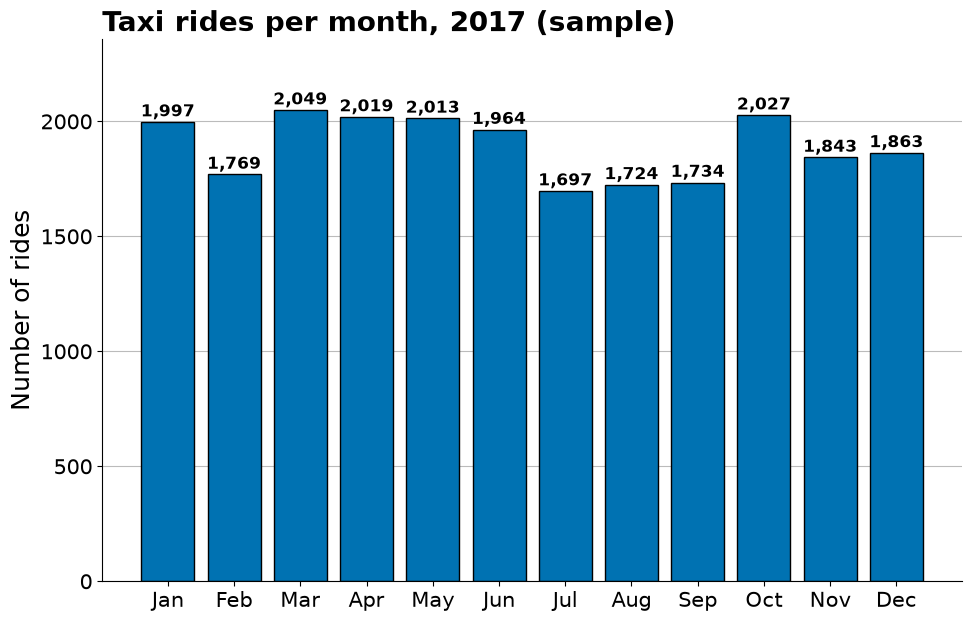

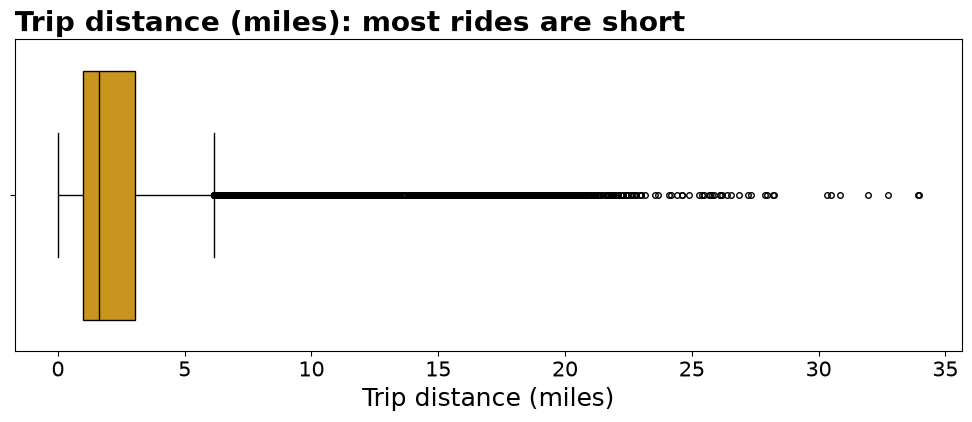

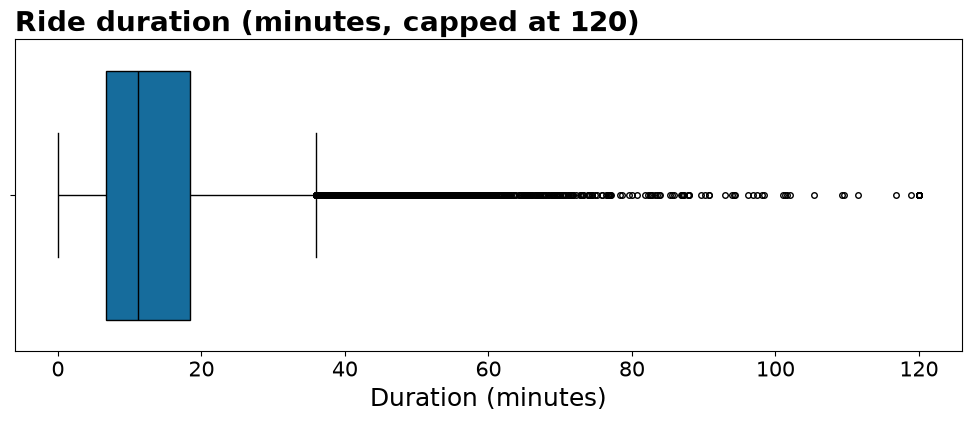

In [6]:
plt.rcParams.update({'font.size':16,'axes.titlesize':20,'axes.labelsize':18,'xtick.labelsize':15,'ytick.labelsize':15,'axes.edgecolor':'black'})
BLUE, ORANGE = '#0072B2', '#E69F00'
mn = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(10,6.5))
bars = ax.bar(mn, month.rides.values, color=BLUE, edgecolor='black')
ax.set_title('Taxi rides per month, 2017 (sample)', weight='bold', loc='left')
ax.set_ylabel('Number of rides'); ax.set_ylim(0, month.rides.max()*1.15)
for b,v in zip(bars, month.rides.values): ax.text(b.get_x()+b.get_width()/2, v+25, f'{v:,}', ha='center', fontsize=12, weight='bold')
ax.spines[['top','right']].set_visible(False); ax.grid(axis='y', color='#BBBBBB', lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('rides_by_month.png', dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(10,4.5))
sns.boxplot(x=df.trip_distance, color=ORANGE, linecolor='black', ax=ax, fliersize=4)
ax.set_title('Trip distance (miles): most rides are short', weight='bold', loc='left'); ax.set_xlabel('Trip distance (miles)')
plt.tight_layout(); plt.savefig('trip_distance_box.png', dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(10,4.5))
sns.boxplot(x=df.duration_min.clip(lower=0, upper=120), color=BLUE, linecolor='black', ax=ax, fliersize=4)
ax.set_title('Ride duration (minutes, capped at 120)', weight='bold', loc='left'); ax.set_xlabel('Duration (minutes)')
plt.tight_layout(); plt.savefig('duration_box.png', dpi=200); plt.show()